**Implement Grover's algorithm on a 3-qubit system to search for the target states '101' and '100'.**

In [ ]:
## Installation required
## In qbraid we need to run the cell everytime we open a new session

!pip install qiskit[visualization]
# Use the following if you are on MacOS/zsh
#!pip install 'qiskit[visualization]'==1.1.0
!pip install qiskit_ibm_runtime
!pip install qiskit_aer
!pip install matplotlib
!pip install pylatexenc
!pip install prototype-zne

  Using cached qiskit-2.2.3-cp39-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (12 kB)
  Using cached rustworkx-0.17.1-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (10 kB)
  Using cached scipy-1.16.3-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (62 kB)
  Using cached dill-0.4.0-py3-none-any.whl.metadata (10 kB)
  Using cached stevedore-5.5.0-py3-none-any.whl.metadata (2.2 kB)
  Using cached pydot-4.0.1-py3-none-any.whl.metadata (11 kB)
  Using cached pylatexenc-2.10-py3-none-any.whl
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached qiskit-2.2.3-cp39-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (8.0 MB)
Using cached dill-0.4.0-py3-none-any.whl (119 kB)
Using cached rustworkx-0.17.1-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (2.2 MB)
Using cached scipy-1.16.3

In [ ]:
import qiskit
qiskit.__version__

'2.2.3'

In [ ]:
## Import packages

#from math import pi
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit import Gate
from qiskit_aer import AerSimulator, QasmSimulator
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import plot_histogram
import time

In [ ]:
## Circuit setup
key_size = 3
n_marked = 2 #n_marked: Number of marked states
#num_qubits = 3*key_size+1
r_key = QuantumRegister(key_size, 'r_key')
z = QuantumRegister(2, 'z')
target = QuantumRegister(2, 'target')
r_ancilla = QuantumRegister(2, 'r_ancilla')
r_output = QuantumRegister(1, name = 'r_output')

cr = ClassicalRegister(key_size, name='c')
qc = QuantumCircuit(r_key, z, target, r_ancilla, r_output, cr)

In [ ]:
print(qc.qregs)

[QuantumRegister(3, 'r_key'), QuantumRegister(2, 'z'), QuantumRegister(2, 'target'), QuantumRegister(2, 'r_ancilla'), QuantumRegister(1, 'r_output')]


In [ ]:
def our_oracle(qc):
    qc.cx(r_key[0], z[0])
    qc.cx(r_key[1], z[1])

    #Checking whether the generated key is equal to the given key
    for i in range(2):
        qc.cx(target[i], r_ancilla[i])
        qc.cx(z[i], r_ancilla[i])
        qc.x(r_ancilla[i])

    #Set 'output' bit if the key is matched
    qc.mcx(r_ancilla, r_output)

    qc.barrier()

    #Uncompute to reset ancilla and key qubits
    for i in range(2):
        qc.x(r_ancilla[i])
        qc.cx(target[i], r_ancilla[i])
        qc.cx(z[i], r_ancilla[i])
    qc.barrier()

    qc.cx(r_key[1], z[1])
    qc.cx(r_key[0], z[0])


In [ ]:
#The diffuser function is available in Qiskit; Courtesey: https://github.com/Qiskit/textbook/blob/main/notebooks/ch-algorithms/grover.ipynb
def diffuser(nqubits):
    qc = QuantumCircuit(nqubits)
    #nqubits = nqubits - 2
    #Apply transformation |s> -> |00...0> (H gates)
    for qubit in range(nqubits):
        qc.h(qubit)
    #Apply transformation |00...0> -> |11...1> (X gates)
    for qubit in range(nqubits):
        qc.x(qubit)
    #Do multi-controlled Z gate
    qc.h(nqubits - 1)
    qc.mcx(list(range(nqubits - 1)), nqubits - 1) #multi-controlled Toffoli; replaced with qc.mct(list(range(nqubits - 1)), nqubits - 1)
    qc.h(nqubits - 1)
    #Apply transformation |11...1> -> |00...0> (X gates)
    for qubit in range(nqubits):
        qc.x(qubit)
    #Apply transformation |00...0> -> |s> (H gates)
    for qubit in range(nqubits):
        qc.h(qubit)
    #We will return the diffuser as a gate
    U_s = qc.to_gate()
    #U_s.name = "U$_s$"
    return U_s


In [ ]:
#Loading search key given as an input
marked_states = ['101','100']
qc.x(target[0]) # We make the state of 'target' as '10'
#######################
#Preparing key in a superposition state
for i in range(key_size):
    qc.h(r_key[i])
#######################
#Preparing output qubit
qc.x(r_output)
qc.h(r_output)
#qc.barrier()
#######################

#First Iteration
our_oracle(qc)
#qc.barrier()
qc.append(diffuser(key_size), r_key)
#qc.barrier()

#Second Iteration (Not required in this case of 2 targets, in this iteration the amplitudes of the targets will decrease)
"""our_oracle(qc)
#qc.barrier()
qc.append(diffuser(key_size), r_key)
#qc.barrier()"""


'our_oracle(qc)\n#qc.barrier()\nqc.append(diffuser(key_size), r_key)\n#qc.barrier()'

In [ ]:
#qc.measure_all()
qc.measure(r_key, cr)

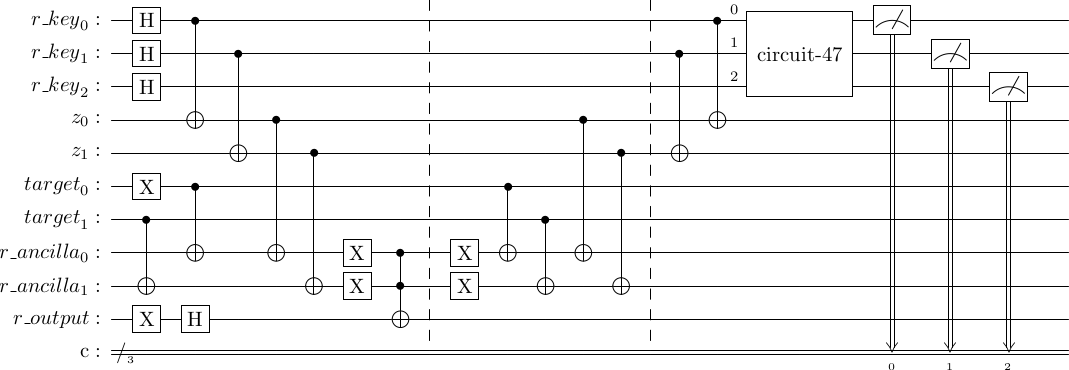

In [ ]:
qc.draw('latex')

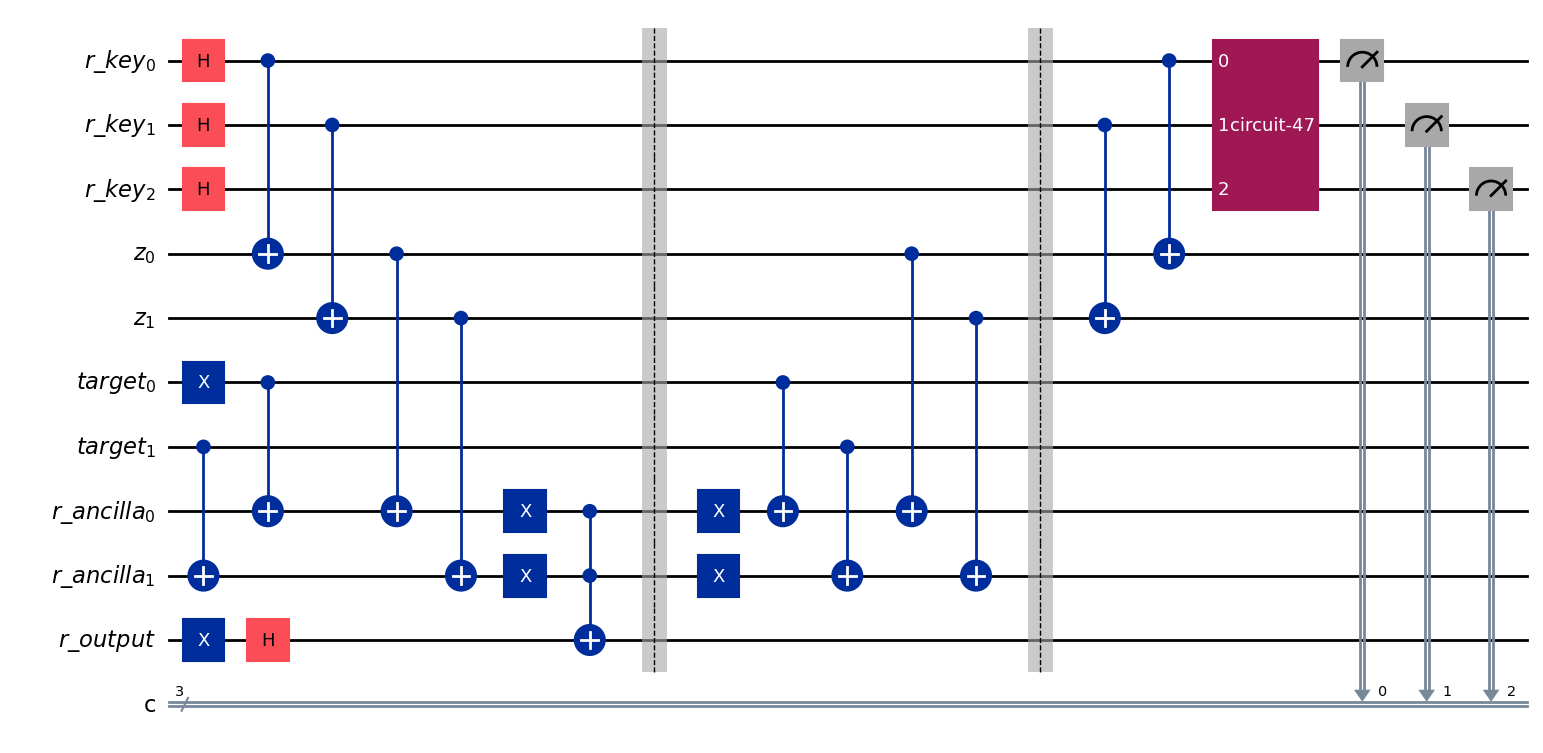

In [ ]:
qc.draw('mpl')

In [ ]:
print("Circuit depth: ", qc.depth())

Circuit depth:  11


In [ ]:
## Running in IBM Quantum hardware

# Set up service by using open plan instance. you can delete or modify to use another instance

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token="7B56VzjjjnsHLgubSpHxjxF2uvmcao-u8W4puO3tslBA",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/c20d31e220944e43bac65bf980fac4b2:67202f51-ec7f-4c27-a3d4-81ab40bde4a5::"
) #Token: Your IBM QUANTUM Token (i.e., Your API Key), instance: Your INSTANCE CRN or name
## You can get your API Key after logging in at https://quantum.cloud.ibm.com/ (https://quantum.ibm.com/ is obsolete from July 01, 2025)
## Reference: https://quantum.cloud.ibm.com/docs/en/migration-guides/classic-iqp-to-cloud-iqp
## If you are using cloud environment, you can disable your key as mentioned in the above link, after successfully running the entire code

print(service.backends())

#backend = service.backend("ibm_torino")
backend = service.least_busy(simulator=False, operational=True)
print(backend)

# Generate ISA circuits to run the quantum circuit
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)

# Create a Sampler object
sampler = Sampler(backend)

# Submit the circuit to the sampler
job = sampler.run([isa_circuit], shots=1024)

print(job.usage_estimation)
# Store the result
result = job.result()[0]
counts = result.data.c.get_counts()

qiskit_runtime_service._discover_account:WARNING:2025-11-01 19:04:53,437: Loading account with the given token. A saved account will not be used.


[<IBMBackend('ibm_brisbane')>, <IBMBackend('ibm_fez')>, <IBMBackend('ibm_torino')>, <IBMBackend('ibm_marrakesh')>]
<IBMBackend('ibm_fez')>
{'quantum_seconds': None}


In [ ]:
# Simulate the quantum circuit
backend_sim = QasmSimulator(method='matrix_product_state')
n_o_shots = 1024
result = backend_sim.run(qc.decompose(reps=1), shots=n_o_shots).result()
## Obtain results
counts = result.get_counts()
print (counts)

{'101': 496, '001': 528}


In [ ]:
b, c = max(counts.items(), key=lambda x: x[1])
d, e = min(counts.items(), key=lambda x: x[1])
#print("Key is :", b[::-1], "with probability =", c/n_o_shots, "and count =", c)

Text(38.347222222222214, 0.5, 'Count')

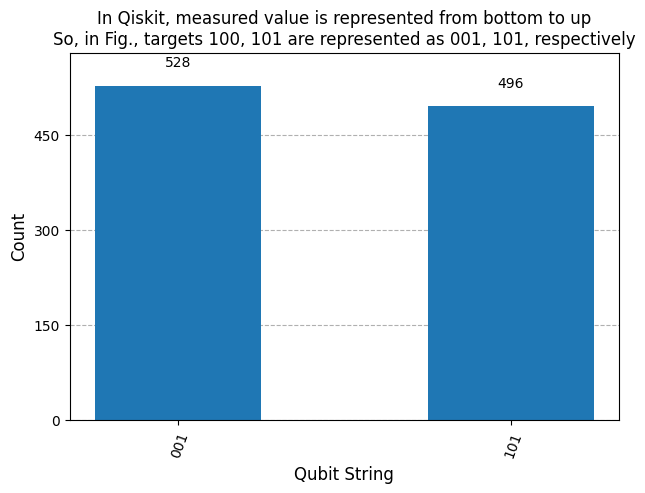

In [ ]:
%matplotlib inline
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

#figure = plot_histogram(counts, title = "In Qiskit, Actual search key {0} is represented as {1} below and\nrecovered with probability {2:.2f}".format(b[::-1],b,c/n_o_shots))
figure = plot_histogram(counts, title = "In Qiskit, measured value is represented from bottom to up\nSo, in Fig., targets {0}, {1} are represented as {2}, {3}, respectively".format(b[::-1],d[::-1],b,d))
# Label the axes
ax = figure.gca()  # Get the current axis
ax.set_xlabel('Qubit String', fontsize=12)  # Set x-axis label
ax.set_ylabel('Count', fontsize=12)  # Set y-axis label

# Save the plot as an image
#figure.savefig("histogram.png")

In [ ]:
# Circuit simulation

backend = QasmSimulator(method='automatic') # 'automatic' or 'matrix_product_state' or 'density_matrix'
sampler = Sampler(backend)
job = sampler.run([qc], shots=1024)
result = job.result()[0]

AerError: 'unknown instruction: circuit-58'